# Practical Session 4 - Overfitting, data leakage and model generalization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

## Part A - Data inspection and potential leakage

In [2]:
df = pd.read_csv("hybrid_student_performance_1200.csv")
print(df.shape)
print(df.dtypes)
print(df.describe().to_string())
missing = (df.isna().mean() * 100).round(2)
print(missing[missing > 0])
df["timestamp"] = pd.to_datetime(df["timestamp"])

(1200, 36)
student_id                    str
timestamp                     str
year_class                    str
program_stream                str
age                         int64
gender                        str
cgpa_category                 str
academic_satisfaction         str
study_hours_daily             str
daily_productivity        float64
revision_frequency            str
focus_duration                str
screen_time_non_study         str
main_distractor               str
study_consistency             str
tasks_on_time                 str
preparation_status            str
career_goal_clarity           str
skills_developing             str
energy_level              float64
stress_level              float64
routine_rating            float64
sleepy_during_study           str
sleep_hours                   str
career_interest               str
online_courses                str
projects_internships          str
programming_foundation        str
events_participation          str
ass

**A.1** The dataset has 1,200 rows and 36 columns. 13 columns have missing values, between 2.33% and 4.83% of the rows (for example sleep_hours 4.58%, stress_level 2.92%, revision_frequency 2.83% and daily_productivity 2.83%).

In [3]:
print("All columns:", df.duplicated().sum())
print("Without student_id:", df.drop(columns=["student_id"]).duplicated().sum())
print("Ignoring timestamp:", df.drop(columns=["timestamp"]).duplicated().sum())
print("Ignoring student_id and timestamp:", df.drop(columns=["student_id", "timestamp"]).duplicated().sum())

All columns: 0
Without student_id: 0
Ignoring timestamp: 0
Ignoring student_id and timestamp: 0


**A.2** There are no duplicates in the file: 0 in the four checks (all columns, without student_id, ignoring timestamp, and ignoring both). Part B.2 adds duplicates on purpose.

In [4]:
df["final_cgpa"] = df["cgpa_category"].map({"5.0 – 6.9": 5.95, "7.0 – 8.4": 7.70, "8.5 – 9.4": 8.95, "9.5 – 10.0": 9.75})
df["study_hours"] = df["study_hours_daily"].map({"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 2.5})
df["sleep_hours"] = df["sleep_hours"].map({"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 8.5})
df["attendance_rate"] = df["attendance_percentage"].map({"Less than 50%": 40, "50% – 65%": 57.5, "66% – 75%": 70.5, "76% – 85%": 80.5, "Above 85%": 92.5})
df["study_consistency"] = df["study_consistency"].map({"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2})
df["tasks_on_time"] = df["tasks_on_time"].map({"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3})
df["assignments_on_time"] = df["assignments_on_time"].map({"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3})
df["revision_frequency"] = df["revision_frequency"].map({"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3})
df["career_goal_clarity"] = df["career_goal_clarity"].map({"Not clear": 0, "Somewhat clear": 1, "Very clear": 2})
df["submission_day"] = (df["timestamp"] - df["timestamp"].min()).dt.total_seconds() / 86400
df["cohort_code"] = df["program_stream"] + " | " + df["year_class"]

effort = pd.concat([df["study_hours"] / 2.5, df["attendance_rate"] / 100, df["study_consistency"] / 2,
                    df["tasks_on_time"] / 3, df["assignments_on_time"] / 3, df["revision_frequency"] / 3], axis=1)
df["effort_index"] = effort.mean(axis=1)

features = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency", "tasks_on_time",
            "assignments_on_time", "revision_frequency", "career_goal_clarity", "daily_productivity",
            "stress_level", "age", "submission_day"]
correlations = df[features + ["effort_index"]].corrwith(df["final_cgpa"]).sort_values()
print(correlations.round(3))

age                   -0.024
sleep_hours           -0.010
stress_level           0.019
submission_day         0.020
revision_frequency     0.071
assignments_on_time    0.076
tasks_on_time          0.097
career_goal_clarity    0.121
daily_productivity     0.132
study_hours            0.297
study_consistency      0.322
attendance_rate        0.365
effort_index           0.377
dtype: float64


**A.3** The strongest correlations with final_cgpa are attendance_rate (0.365), study_consistency (0.322) and study_hours (0.297). effort_index (0.377) is the strongest because it combines these features. The weakest are sleep_hours (-0.010), stress_level (0.019), submission_day (0.020) and age (-0.024): almost no linear relation. All the correlations are small (the maximum is 0.38), so the target is noisy and hard to predict.

In [5]:
print(pd.crosstab(df["cgpa_category"], df["performance_risk_level"]))

performance_risk_level  High Risk  Low Risk  Moderate Risk
cgpa_category                                             
5.0 – 6.9                     188         0             48
7.0 – 8.4                     221         4            195
8.5 – 9.4                      39        89            234
9.5 – 10.0                      4        83             95


**A.4** No, it cannot be used as a feature. The risk level is built from the CGPA, so it contains information about the target (target leakage): no student of the band 5.0 - 6.9 is Low Risk (0 of 236), and almost no student of the two best bands is High Risk (39 and 4). Also, it is not known before the CGPA. A model using it would get a very good score that is not real.

In [6]:
cohort_counts = df["cohort_code"].value_counts()
print("Number of categories:", len(cohort_counts))
print("Categories with fewer than 10 observations:", (cohort_counts < 10).sum())
print(cohort_counts.tail(12))

Number of categories: 42
Categories with fewer than 10 observations: 12
cohort_code
BCom | Second Year (PG)                  9
BA | First Year (PG)                     8
BA | First Year (FY)                     7
BSc Cyber Security | Second Year (PG)    7
BCom | Final Year                        6
BBA | First Year (PG)                    6
BA | Second Year (PG)                    6
BBA | Final Year                         6
BSc IT | Second Year (PG)                5
BSc Cyber Security | Final Year          4
BBA | Second Year (PG)                   3
BA | Final Year                          3
Name: count, dtype: int64


**A.5** There are 42 cohort_code categories, and 12 of them have fewer than 10 observations (the smallest has only 3).

Already in chronological order: False


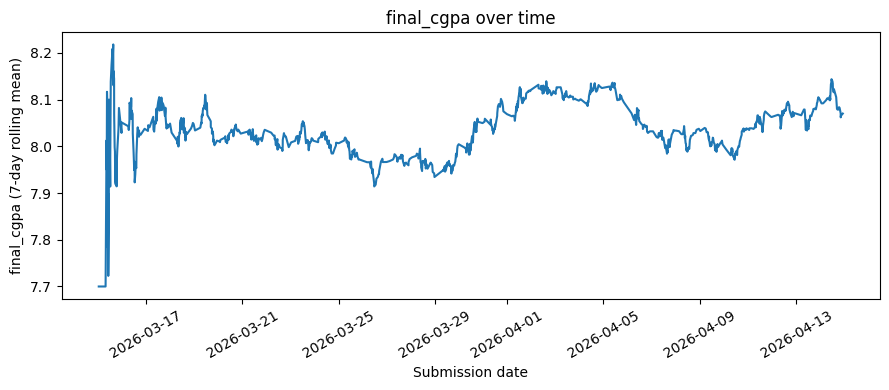

In [7]:
print("Already in chronological order:", df["timestamp"].is_monotonic_increasing)
df = df.sort_values("timestamp").reset_index(drop=True)
rolling = df.set_index("timestamp")["final_cgpa"].rolling("7D").mean()
plt.figure(figsize=(9, 4))
plt.plot(rolling.index, rolling.values)
plt.xlabel("Submission date")
plt.ylabel("final_cgpa (7-day rolling mean)")
plt.title("final_cgpa over time")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**A.6** The file is not in chronological order, so it was sorted by timestamp. The 7-day rolling mean of final_cgpa stays between about 7.9 and 8.15 during the whole period (the first days are noisy because there are very few responses). There is no trend or drift, which is consistent with the correlation of 0.020 between submission_day and the target.

**Risks found in the data**
- **performance_risk_level** is derived from the target, so using it gives target leakage. It is removed.
- **Time order:** the rows are not sorted, and submission_day increases with time. A random split mixes the time periods and gives an optimistic score, so a chronological split is needed. In that split, the test values of submission_day are outside the training range.
- **Possible duplicate submissions:** there are none in the file, but a student can submit the form twice. If a copy goes to training and another to testing, the test score becomes too good (B.2).
- **cohort_code** has 42 categories and 12 have fewer than 10 rows. A model can memorize these rare categories (overfitting), and a target encoding of them is noisy.
- **Missing values (2% to 5%) and a noisy target:** the imputation and the scaling must be learned from the training data only (B.3), and the weak correlations mean that complex models can easily fit noise.

## Part B - Impact of data leakage and evaluation strategy

In [8]:
X = df[features]
y = df["final_cgpa"]
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
train_df = df.iloc[:split]
print("Train:", len(X_train), "Test:", len(X_test))

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

def baseline_rmse(Xtr, ytr, Xte, yte):
    return rmse(yte, DummyRegressor().fit(Xtr, ytr).predict(Xte))

def train_test_rmse(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    return rmse(ytr, model.predict(Xtr)), rmse(yte, model.predict(Xte))

def new_tree():
    return make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(random_state=42))

summary_b = []
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.2, random_state=42)
tr, te = train_test_rmse(new_tree(), Xr_train, yr_train, Xr_test, yr_test)
summary_b.append(["B.1 Decision tree, random split", tr, te, baseline_rmse(Xr_train, yr_train, Xr_test, yr_test)])
tr, te = train_test_rmse(new_tree(), X_train, y_train, X_test, y_test)
summary_b.append(["B.1 Decision tree, chronological split", tr, te, baseline_rmse(X_train, y_train, X_test, y_test)])
print(pd.DataFrame(summary_b, columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline RMSE"]).round(3).to_string(index=False))

Train: 960 Test: 240
                              Strategy  Training RMSE  Testing RMSE  Baseline RMSE
       B.1 Decision tree, random split            0.0         1.579          1.338
B.1 Decision tree, chronological split            0.0         1.975          1.236


**B.1** The decision tree without depth limit memorizes the training data (training RMSE 0.000 in both cases), so the training score tells nothing. The testing RMSE is 1.579 with the random split and 1.975 with the chronological split, while the baseline gives 1.338 and 1.236. In both cases the tree is worse than the baseline, so it overfits. The random split looks better because the test students are mixed in time with the training students, so for each test row there are training rows submitted at almost the same time. In the chronological split, all the test rows come after the training period, like in real use (we predict new students from past ones), so the error is higher and more realistic.

In [9]:
dup = df.sample(frac=0.15, random_state=42).copy()
rng = np.random.default_rng(42)
period = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
dup["timestamp"] = df["timestamp"].min() + pd.to_timedelta(rng.uniform(0, period, len(dup)), unit="s")

aug = pd.concat([df, dup]).sort_values("timestamp").reset_index(drop=True)
aug["submission_day"] = (aug["timestamp"] - aug["timestamp"].min()).dt.total_seconds() / 86400
print("Rows after adding duplicates:", len(aug))

answer_cols = [c for c in df.columns if c not in ["timestamp", "submission_day"]]

split_aug = int(len(aug) * 0.8)
key = aug[answer_cols].fillna("NA").astype(str).agg("|".join, axis=1)
leaked = key.iloc[split_aug:].isin(set(key.iloc[:split_aug])).sum()
print("Test rows that also have a copy in the training set:", leaked, "out of", len(aug) - split_aug)

Xa, ya = aug[features], aug["final_cgpa"]
tr, te = train_test_rmse(new_tree(), Xa.iloc[:split_aug], ya.iloc[:split_aug], Xa.iloc[split_aug:], ya.iloc[split_aug:])
summary_b.append(["B.2 Split before removing duplicates", tr, te, baseline_rmse(Xa.iloc[:split_aug], ya.iloc[:split_aug], Xa.iloc[split_aug:], ya.iloc[split_aug:])])

clean = aug.drop_duplicates(subset=answer_cols, keep="first").reset_index(drop=True)
print("Rows after removing duplicates:", len(clean))
split_clean = int(len(clean) * 0.8)
Xc, yc = clean[features], clean["final_cgpa"]
tr, te = train_test_rmse(new_tree(), Xc.iloc[:split_clean], yc.iloc[:split_clean], Xc.iloc[split_clean:], yc.iloc[split_clean:])
summary_b.append(["B.2 Remove duplicates, then split", tr, te, baseline_rmse(Xc.iloc[:split_clean], yc.iloc[:split_clean], Xc.iloc[split_clean:], yc.iloc[split_clean:])])

Rows after adding duplicates: 1380


Test rows that also have a copy in the training set: 50 out of 276
Rows after removing duplicates: 1200


**B.2** After adding the duplicates there are 1,380 rows. A copy has the same answers but a new random timestamp, so it can be on the other side of the chronological split than the original. Here 50 of the 276 test rows have an exact copy in the training set. The tree has memorized the training rows, so it predicts these test rows correctly and the test score looks better. The testing RMSE is 1.503 (baseline 1.277) when we split before removing the duplicates, and 1.718 (baseline 1.218) when we remove them before splitting. So the score with duplicates is too optimistic. The right way is to remove the duplicates first and then split.

In [10]:
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X_all_scaled = prep.fit_transform(X)
knn = KNeighborsRegressor(n_neighbors=10)
tr, te = train_test_rmse(knn, X_all_scaled[:split], y_train, X_all_scaled[split:], y_test)
summary_b.append(["B.3 KNN, scaler fitted on all data", tr, te, baseline_rmse(X_train, y_train, X_test, y_test)])

knn_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=10))
tr, te = train_test_rmse(knn_pipe, X_train, y_train, X_test, y_test)
summary_b.append(["B.3 KNN, scaler fitted on training only", tr, te, baseline_rmse(X_train, y_train, X_test, y_test)])

table_b = pd.DataFrame(summary_b, columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline RMSE"]).round(3)
print(table_b.to_string(index=False))

                               Strategy  Training RMSE  Testing RMSE  Baseline RMSE
        B.1 Decision tree, random split          0.000         1.579          1.338
 B.1 Decision tree, chronological split          0.000         1.975          1.236
   B.2 Split before removing duplicates          0.000         1.503          1.277
      B.2 Remove duplicates, then split          0.000         1.718          1.218
     B.3 KNN, scaler fitted on all data          1.069         1.157          1.236
B.3 KNN, scaler fitted on training only          1.066         1.147          1.236


**B.3** The two testing RMSE are almost the same: 1.157 when the scaler is fitted on all the data and 1.147 when it is fitted on the training data only (the leaky version is even slightly worse, so the gap is just noise). The gap is small because the scaler only learns a mean and a standard deviation, and with 1,200 rows these values hardly change. But the principle is still important: the test data must stay unseen, and any statistic learned from it (the mean and std of the scaler, the median used for imputation) gives the model information about the test set. With a smaller dataset, outliers or a drift in time, the effect can be much bigger. In real use the new data does not exist when we train the model, so all the preprocessing must be learned from the training data only, inside a Pipeline.

## Part C - Understanding and diagnosing overfitting

max_depth  Training RMSE  Testing RMSE  Generalization gap
        1          1.179         1.159              -0.020
        2          1.139         1.127              -0.013
        3          1.102         1.068              -0.034
        5          1.009         1.335               0.326
       10          0.539         1.936               1.397
       20          0.000         1.975               1.975
     None          0.000         1.975               1.975
Baseline RMSE: 1.236


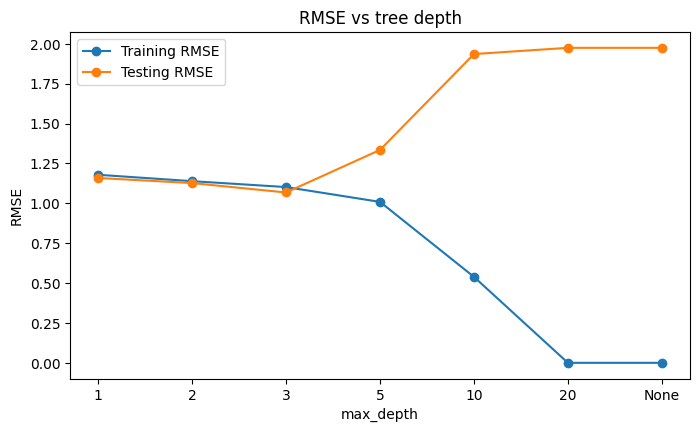

In [11]:
depths = [1, 2, 3, 5, 10, 20, None]
rows_c1 = []
for d in depths:
    model = make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(max_depth=d, random_state=42))
    tr, te = train_test_rmse(model, X_train, y_train, X_test, y_test)
    rows_c1.append([str(d), tr, te, te - tr])
table_c1 = pd.DataFrame(rows_c1, columns=["max_depth", "Training RMSE", "Testing RMSE", "Generalization gap"]).round(3)
print(table_c1.to_string(index=False))
print("Baseline RMSE:", round(baseline_rmse(X_train, y_train, X_test, y_test), 3))

plt.figure(figsize=(8, 4.5))
plt.plot(table_c1["max_depth"], table_c1["Training RMSE"], marker="o", label="Training RMSE")
plt.plot(table_c1["max_depth"], table_c1["Testing RMSE"], marker="o", label="Testing RMSE")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("RMSE vs tree depth")
plt.legend()
plt.show()

**C.1** The training RMSE decreases when the depth increases (1.179 for depth 1 and 0.000 for depth 20 and None). The testing RMSE decreases until depth 3 (1.068) and then increases: 1.335 for depth 5, 1.936 for depth 10 and 1.975 for depth 20 and None. The generalization gap is small or negative until depth 3 (-0.034), becomes positive at depth 5 (0.326) and grows to 1.975. So the model starts to overfit at depth 5, and depth 3 is the best one. The deepest trees are much worse than the baseline (1.236).

 Degree  CV RMSE
      1    1.177
      2    1.178
      3    1.179
      5    1.185
      9    1.188
     15    1.294


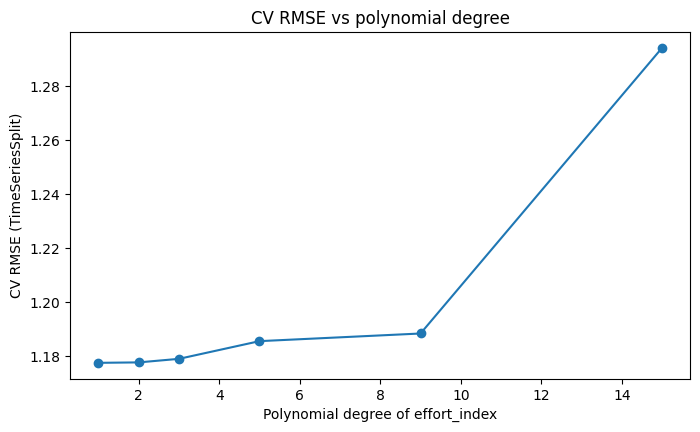

In [12]:
degrees = [1, 2, 3, 5, 9, 15]
tscv = TimeSeriesSplit(n_splits=5)
Xe_train = train_df[["effort_index"]]
cv_rmse = []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    scores = cross_val_score(model, Xe_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error")
    cv_rmse.append(-scores.mean())
table_c2 = pd.DataFrame({"Degree": degrees, "CV RMSE": np.round(cv_rmse, 3)})
print(table_c2.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, cv_rmse, marker="o")
plt.xlabel("Polynomial degree of effort_index")
plt.ylabel("CV RMSE (TimeSeriesSplit)")
plt.title("CV RMSE vs polynomial degree")
plt.show()

**C.2** The CV RMSE of the polynomial models is almost constant: 1.177 for degree 1 and 1.188 for degree 9. Only degree 15 shows a clear increase (1.294). The effect is much smaller than in C.1, where the testing RMSE went from 1.068 to 1.975. The reason is that this model uses only one feature, effort_index, and a polynomial of one variable is a smooth curve that cannot memorize 960 rows (many students have close values of effort_index). A deep tree uses 12 features, including submission_day, and can isolate each training row (training RMSE of 0). Also, the relation between effort_index and the target is weak and almost linear, so the simple degree 1 model is already the best.

## Part D - Improving model generalization

In [13]:
def cv_rmse_of(model, Xdata):
    scores = cross_val_score(model, Xdata, y_train, cv=tscv, scoring="neg_root_mean_squared_error")
    return -scores.mean()

D1_train = train_df[features + ["cohort_code"]]
median_num = SimpleImputer(strategy="median")

pre_group = ColumnTransformer([("num", median_num, features),
                               ("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False), ["cohort_code"])])
pre_target = ColumnTransformer([("num", median_num, features),
                                ("cat", TargetEncoder(cv=5, shuffle=False), ["cohort_code"])])
pre_drop = ColumnTransformer([("num", median_num, features)])

rows_d1 = []
for name, pre in [("Rare-category grouping", pre_group), ("Target encoding", pre_target), ("Feature removal", pre_drop)]:
    model = make_pipeline(pre, DecisionTreeRegressor(max_depth=5, random_state=42))
    rows_d1.append([name, cv_rmse_of(model, D1_train)])
table_d1 = pd.DataFrame(rows_d1, columns=["Treatment of cohort_code", "Validation RMSE"]).round(4)
print(table_d1.to_string(index=False))

Treatment of cohort_code  Validation RMSE
  Rare-category grouping           1.2368
         Target encoding           1.3004
         Feature removal           1.2549


**D.1** Rare-category grouping gives the best validation RMSE (1.2368), followed by feature removal (1.2549) and target encoding (1.3004). The differences are small, so cohort_code is only slightly informative. Target encoding is the worst because the target mean of a small category is noisy, so it adds noise. I keep the rare-category grouping because it has the lowest validation RMSE.

In [14]:
use_cohort = True
features_no_day = [f for f in features if f != "submission_day"]

def make_pre(num_features):
    parts = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features)]
    if use_cohort:
        parts.append(("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False), ["cohort_code"]))
    return ColumnTransformer(parts)

def columns_for(num_features):
    if use_cohort:
        return num_features + ["cohort_code"]
    return num_features

rows_d2 = []
for name, make in [("Linear Regression", lambda: LinearRegression()),
                   ("Decision Tree (depth 5)", lambda: DecisionTreeRegressor(max_depth=5, random_state=42)),
                   ("Gradient Boosting", lambda: GradientBoostingRegressor(n_estimators=60, learning_rate=0.05, max_depth=3, random_state=42))]:
    with_day = make_pipeline(make_pre(features), make())
    without_day = make_pipeline(make_pre(features_no_day), make())
    rows_d2.append([name, cv_rmse_of(with_day, train_df[columns_for(features)]), cv_rmse_of(without_day, train_df[columns_for(features_no_day)])])
table_d2 = pd.DataFrame(rows_d2, columns=["Model", "With submission_day", "Without submission_day"]).round(4)
print(table_d2.to_string(index=False))

                  Model  With submission_day  Without submission_day
      Linear Regression               1.1383                  1.1248
Decision Tree (depth 5)               1.2368                  1.2002
      Gradient Boosting               1.1412                  1.1292


**D.2** Without submission_day the validation RMSE is lower for the three models: Linear Regression 1.1248 against 1.1383, Decision Tree 1.2002 against 1.2368 and Gradient Boosting 1.1292 against 1.1412. I remove submission_day for the rest of the session. It is not a characteristic of the student (it is only the time of the survey), it has almost no correlation with the target (0.020), and in the chronological test set all its values are outside the training range, so the models cannot use it correctly.

In [15]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

def poly5(regressor):
    return make_pipeline(PolynomialFeatures(5, include_bias=False), StandardScaler(), regressor)

rows_d3 = [["Linear Regression", "-", cv_rmse_of(poly5(LinearRegression()), Xe_train)]]
for alpha in alphas:
    rows_d3.append(["Ridge", alpha, cv_rmse_of(poly5(Ridge(alpha=alpha)), Xe_train)])
for alpha in alphas:
    rows_d3.append(["Lasso", alpha, cv_rmse_of(poly5(Lasso(alpha=alpha, max_iter=100000)), Xe_train)])
table_d3 = pd.DataFrame(rows_d3, columns=["Model", "Alpha", "Validation RMSE"])
print(table_d3.round(4).to_string(index=False))

ridge_rows = table_d3[table_d3["Model"] == "Ridge"]
lasso_rows = table_d3[table_d3["Model"] == "Lasso"]
best_ridge_alpha = ridge_rows.loc[ridge_rows["Validation RMSE"].idxmin(), "Alpha"]
best_lasso_alpha = lasso_rows.loc[lasso_rows["Validation RMSE"].idxmin(), "Alpha"]
print("Best Ridge alpha:", best_ridge_alpha, "| Best Lasso alpha:", best_lasso_alpha)

coef_lr = poly5(LinearRegression()).fit(Xe_train, y_train)[-1].coef_
coef_ridge = poly5(Ridge(alpha=best_ridge_alpha)).fit(Xe_train, y_train)[-1].coef_
coef_lasso = poly5(Lasso(alpha=best_lasso_alpha, max_iter=100000)).fit(Xe_train, y_train)[-1].coef_
coefs = pd.DataFrame({"Linear": coef_lr, "Ridge": coef_ridge, "Lasso": coef_lasso}, index=["x", "x2", "x3", "x4", "x5"])
print(coefs.round(4))
print("Lasso coefficients exactly zero:", int((coef_lasso == 0).sum()), "out of", len(coef_lasso))

            Model  Alpha  Validation RMSE
Linear Regression      -           1.1854
            Ridge  0.001           1.1808
            Ridge   0.01           1.1800
            Ridge    0.1           1.1790
            Ridge      1           1.1784
            Ridge     10           1.1782
            Ridge    100           1.1805
            Lasso  0.001           1.1781
            Lasso   0.01           1.1771
            Lasso    0.1           1.1772
            Lasso      1           1.2680
            Lasso     10           1.2680
            Lasso    100           1.2680
Best Ridge alpha: 10 | Best Lasso alpha: 0.01
     Linear   Ridge  Lasso
x    8.8312  0.3941  0.471
x2 -37.7527  0.1560  0.000
x3  66.1826  0.0153  0.000
x4 -52.5146 -0.0489 -0.000
x5  15.7612 -0.0485 -0.000
Lasso coefficients exactly zero: 4 out of 5


**D.3** The best alpha is 10 for Ridge (validation RMSE 1.1782) and 0.01 for Lasso (1.1771), against 1.1854 for the model without penalty. The unregularized degree 5 model has very large coefficients that cancel each other (8.83, -37.75, 66.18, -52.51, 15.76). Ridge shrinks all of them to small values (0.39, 0.16, 0.02, -0.05, -0.05). Lasso keeps only the first term (0.471) and sets 4 of the 5 coefficients exactly to zero, so it becomes a simple linear model. With a big alpha (1 or more) Lasso removes everything and predicts the mean (1.2680), which is underfitting. The improvement is small, but the regularization makes the model much more stable.

Model   Alpha  Validation RMSE
Ridge   0.001           1.1248
Lasso   0.001           1.1234
Ridge   0.010           1.1248
Lasso   0.010           1.1179
Ridge   0.100           1.1246
Lasso   0.100           1.1073
Ridge   1.000           1.1234
Lasso   1.000           1.2680
Ridge  10.000           1.1178
Lasso  10.000           1.2680
Ridge 100.000           1.1136
Lasso 100.000           1.2680
Selected: Lasso alpha = 0.1


Tree validation RMSE: [1.1799 1.162  1.1552 1.2002 1.4677 1.5318 1.5318]
Selected max_depth: 3


Best number of trees: 135 validation RMSE: 1.0754


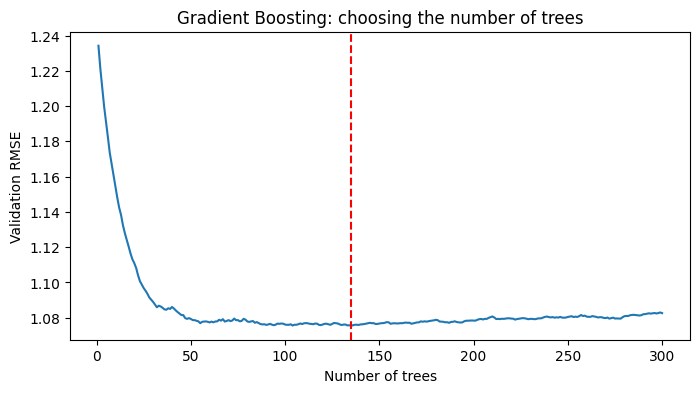

In [16]:
final_features = features_no_day
Xf_train = df[columns_for(final_features)].iloc[:split]
Xf_test = df[columns_for(final_features)].iloc[split:]

def final_pipe(regressor):
    return make_pipeline(make_pre(final_features), regressor)

rows_ridge_lasso = []
for alpha in alphas:
    rows_ridge_lasso.append(["Ridge", alpha, cv_rmse_of(final_pipe(Ridge(alpha=alpha)), Xf_train)])
    rows_ridge_lasso.append(["Lasso", alpha, cv_rmse_of(final_pipe(Lasso(alpha=alpha, max_iter=100000)), Xf_train)])
rl = pd.DataFrame(rows_ridge_lasso, columns=["Model", "Alpha", "Validation RMSE"])
print(rl.round(4).to_string(index=False))
best_rl = rl.loc[rl["Validation RMSE"].idxmin()]
print("Selected:", best_rl["Model"], "alpha =", best_rl["Alpha"])
if best_rl["Model"] == "Ridge":
    rl_model = final_pipe(Ridge(alpha=best_rl["Alpha"]))
else:
    rl_model = final_pipe(Lasso(alpha=best_rl["Alpha"], max_iter=100000))

tree_scores = []
for d in depths:
    tree_scores.append(cv_rmse_of(final_pipe(DecisionTreeRegressor(max_depth=d, random_state=42)), Xf_train))
best_depth = depths[int(np.argmin(tree_scores))]
print("Tree validation RMSE:", np.round(tree_scores, 4))
print("Selected max_depth:", best_depth)
tree_model = final_pipe(DecisionTreeRegressor(max_depth=best_depth, random_state=42))

cut = int(len(Xf_train) * 0.85)
pre_gb = make_pre(final_features).fit(Xf_train.iloc[:cut])
gb_search = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gb_search.fit(pre_gb.transform(Xf_train.iloc[:cut]), y_train.iloc[:cut])
val_errors = [rmse(y_train.iloc[cut:], p) for p in gb_search.staged_predict(pre_gb.transform(Xf_train.iloc[cut:]))]
best_trees = int(np.argmin(val_errors)) + 1
print("Best number of trees:", best_trees, "validation RMSE:", round(min(val_errors), 4))
gb_model = final_pipe(GradientBoostingRegressor(n_estimators=best_trees, learning_rate=0.05, max_depth=3, random_state=42))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 301), val_errors)
plt.axvline(best_trees, color="red", linestyle="--")
plt.xlabel("Number of trees")
plt.ylabel("Validation RMSE")
plt.title("Gradient Boosting: choosing the number of trees")
plt.show()

The selected configurations (features: Part B features without submission_day, with cohort_code grouped): Lasso with alpha = 0.1 (validation RMSE 1.1073, lower than Ridge), a Decision Tree with max_depth = 3 (1.1552) and Gradient Boosting with 135 trees (validation block RMSE 1.0754).

                        Model  Training RMSE  Testing RMSE  Testing R2  Generalization gap
     Baseline (training mean)          1.269         1.236      -0.003              -0.032
            Linear Regression          1.072         1.085       0.227               0.014
          Lasso (alpha = 0.1)          1.106         1.072       0.246              -0.034
Decision Tree (max_depth = 3)          1.102         1.068       0.252              -0.034
Gradient Boosting (135 trees)          0.955         1.059       0.263               0.104


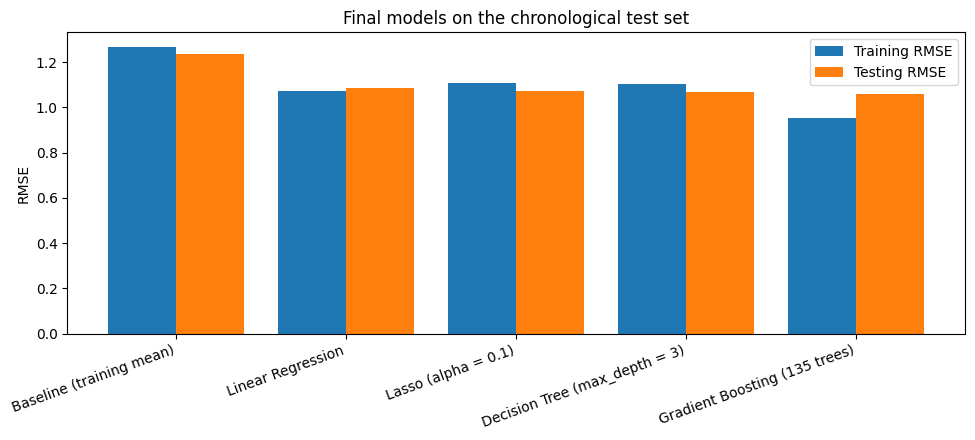

In [17]:
final_models = [("Linear Regression", final_pipe(LinearRegression())),
                ("%s (alpha = %s)" % (best_rl["Model"], best_rl["Alpha"]), rl_model),
                ("Decision Tree (max_depth = %s)" % best_depth, tree_model),
                ("Gradient Boosting (%d trees)" % best_trees, gb_model)]

dummy = DummyRegressor().fit(Xf_train, y_train)
rows_d4 = [["Baseline (training mean)", rmse(y_train, dummy.predict(Xf_train)), rmse(y_test, dummy.predict(Xf_test)), r2_score(y_test, dummy.predict(Xf_test))]]
for name, model in final_models:
    model.fit(Xf_train, y_train)
    rows_d4.append([name, rmse(y_train, model.predict(Xf_train)), rmse(y_test, model.predict(Xf_test)), r2_score(y_test, model.predict(Xf_test))])
table_d4 = pd.DataFrame(rows_d4, columns=["Model", "Training RMSE", "Testing RMSE", "Testing R2"])
table_d4["Generalization gap"] = table_d4["Testing RMSE"] - table_d4["Training RMSE"]
print(table_d4.round(3).to_string(index=False))

pos = np.arange(len(table_d4))
plt.figure(figsize=(10, 4.5))
plt.bar(pos - 0.2, table_d4["Training RMSE"], width=0.4, label="Training RMSE")
plt.bar(pos + 0.2, table_d4["Testing RMSE"], width=0.4, label="Testing RMSE")
plt.xticks(pos, table_d4["Model"], rotation=20, ha="right")
plt.ylabel("RMSE")
plt.title("Final models on the chronological test set")
plt.legend()
plt.tight_layout()
plt.show()

## Final discussion

**1. Best generalization.** Gradient Boosting has the lowest testing RMSE (1.059) and the highest R2 (0.263), but it is very close to the Decision Tree with depth 3 (1.068) and Lasso (1.072). All the models are better than the baseline (1.236), and the differences between them are small.

**2. Largest generalization gap.** Among the final models it is Gradient Boosting (0.104: training RMSE 0.955 and testing RMSE 1.059). The other models have a gap close to zero or slightly negative, like the baseline (-0.032), because the test period is a little easier than the training period. In the whole session the largest gap is the one of the tree without depth limit (1.975 in C.1).

**3. Most effective techniques.** Limiting the depth of the tree was the most effective: the testing RMSE went from 1.975 (no limit) to 1.068 (depth 3). Removing submission_day lowered the validation RMSE of the three models. Regularization reduced the huge coefficients of the degree 5 polynomial (up to 66 before, below 0.5 after) and improved the CV RMSE from 1.1854 to 1.1771. Early stopping chose 135 trees for Gradient Boosting. Removing the duplicates before splitting and using a chronological split did not reduce overfitting, but they gave an honest evaluation.

**4. Validation instead of training performance.** The training performance rewards memorization: the deep tree has a training RMSE of 0 but a testing RMSE of 1.975. A validation set is not used to fit the model, so it estimates the performance on unseen data and lets us choose the complexity, the features and the hyperparameters.

**5. Untouched test set.** If the test set is used to choose features or hyperparameters, its information influences the model, and the final score becomes optimistic because we selected what works best on it. Then there is no unseen data left to give an honest estimate of the real performance.

**6. Modest R2.** The best R2 is 0.263, so the survey features explain only about a quarter of the variance of the CGPA. The answers are self-reported ranges, the target has only four possible values (band midpoints), and the correlations are weak (maximum 0.38), so most of the variation is noise or not captured by the survey. A high score is not always a sign of a good evaluation: the duplicates in B.2 made the test score look better, the risk level would give a very high score because it comes from the target, and a deep tree has a perfect training score but a bad test score.